# Store Sales — Prévision des ventes à 16 jours

**Projet personnel de data science · Python, pandas, LightGBM**

Prévoir les quantités vendues pour chaque couple magasin–famille de produits, à partir de l'historique, des promotions fournies et du calendrier. Le cas d'usage illustre une aide à la planification des approvisionnements ; aucun gain opérationnel ou financier n'a été mesuré.

Le jeu [Store Sales – Time Series Forecasting](https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data) contient **3 000 888 observations**, du **1er janvier 2013 au 15 août 2017** : **54 magasins**, **33 familles**, soit **1 782 séries**. Ces données historiques servent à un projet développé en 2026.

**Validation interne : RMSLE regroupé de 0,3972**, soit environ **12,5 % de réduction** face à une moyenne logarithmique saisonnière sur trois fenêtres de 16 jours. Ces fenêtres ont servi à sélectionner les variantes.

**Soumission officielle du projet : RMSLE Kaggle de 0,43477**, acceptée le **21 novembre 2026**, sur les 28 512 lignes du test du 16 au 31 août 2017. Ce score est distinct de la validation interne.

## Lecture et exécution

Les sorties de calcul et les sept graphiques de données proviennent du notebook Kaggle fourni par l'auteur. Une exécution complète du projet sur Kaggle, en 183,1 secondes, puis une soumission acceptée ont été confirmées le 21 novembre 2026. Cette révision ajoute de la documentation, un chargement portable et des contrôles ; les modèles n'ont pas été réentraînés localement pendant sa préparation. Les compteurs archivés ne prouvent pas une exécution complète de cette révision exacte. Le schéma décrit le protocole de validation.

Dans Kaggle, joindre les données de la compétition via **Add Input**, puis lancer **Save Version → Save & Run All**. L'export `.ipynb` ne transporte pas automatiquement les fichiers de données. En local, placer les cinq CSV requis dans `data/`, ou définir `STORE_SALES_DATA_DIR`, puis suivre le README. Exécuter les cellules dans l'ordre pour reproduire le projet ; conserver les sorties et les versions des bibliothèques de cette exécution.

## 1. Charger les données

Les cinq CSV requis sont identifiés ensemble afin de ne pas mélanger plusieurs jeux de données. Les sorties sont écrites dans `/kaggle/working` sur Kaggle, ou dans `outputs/` en local.

In [2]:
import os
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Lancer Jupyter depuis la racine du projet ou le dossier notebooks.
RACINE_PROJET = (
    Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
)
DOSSIER_SORTIE = (
    Path("/kaggle/working") if Path("/kaggle/working").is_dir()
    else RACINE_PROJET / "outputs"
)
DOSSIER_FIGURES = DOSSIER_SORTIE / "figures"
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)


def trouver_dossier_donnees():
    fichiers_requis = {
        "train.csv", "test.csv", "sample_submission.csv",
        "holidays_events.csv", "stores.csv"
    }

    def dossier_valide(dossier):
        return all((dossier / nom).is_file() for nom in fichiers_requis)

    choix = os.environ.get("STORE_SALES_DATA_DIR")
    if choix:
        dossier = Path(choix).expanduser().resolve()
        if not dossier_valide(dossier):
            raise FileNotFoundError(
                "STORE_SALES_DATA_DIR doit contenir les cinq CSV requis : "
                + ", ".join(sorted(fichiers_requis))
            )
        return dossier

    candidats = []
    if Path("/kaggle/input").is_dir():
        candidats.extend(
            fichier.parent.resolve()
            for fichier in Path("/kaggle/input").rglob("train.csv")
            if dossier_valide(fichier.parent)
        )
    local = RACINE_PROJET / "data"
    if dossier_valide(local):
        candidats.append(local.resolve())
    candidats = list(dict.fromkeys(candidats))

    if len(candidats) != 1:
        raise FileNotFoundError(
            "Impossible d'identifier un seul dossier Store Sales. "
            "Dans Kaggle, ajouter les données de la compétition. "
            "En local, placer les cinq CSV dans data/ ou définir "
            "STORE_SALES_DATA_DIR."
        )
    return candidats[0]


dossier = trouver_dossier_donnees()
chemin = dossier / "train.csv"
df = pd.read_csv(chemin, parse_dates=["date"])
display(df.head())
df.info()


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[ns]
 2   store_nbr    int64         
 3   family       object        
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 137.4+ MB


### Enregistrer l’environnement de la prochaine exécution

Les versions de paquets de l’exécution initiale n’étaient pas toutes enregistrées. Cette cellule les exportera lors de la prochaine exécution.

In [ ]:
import platform
from importlib.metadata import version

versions_execution = {
    "python": platform.python_version(),
    **{nom: version(nom) for nom in ["numpy", "pandas", "matplotlib", "lightgbm"]}
}
display(pd.Series(versions_execution, name="version"))
(DOSSIER_SORTIE / "versions_execution.json").write_text(
    json.dumps(versions_execution, indent=2), encoding="utf-8"
)

## 2. Qualité et couverture du calendrier

Contrôler les clés, les valeurs manquantes, les doublons et les ventes négatives avant de construire les variables.

In [3]:
# 1. Connaître la période couverte
print("Date de début :", df["date"].min())
print("Date de fin :", df["date"].max())

# 2. Compter les magasins et les catégories
print("Nombre de magasins :", df["store_nbr"].nunique())
print("Nombre de familles :", df["family"].nunique())

# 3. Compter les valeurs manquantes par colonne
print("\nValeurs manquantes :")
display(df.isna().sum().to_frame("Nombre"))

# 4. Vérifier les doublons pour une même date, un même
# magasin et une même famille de produits
cles = ["date", "store_nbr", "family"]
print("Nombre de doublons :", df.duplicated(subset=cles).sum())

# 5. Vérifier la présence de ventes négatives
print("Ventes négatives :", (df["sales"] < 0).sum())

assert df["id"].is_unique, "Identifiants d'entraînement dupliqués."
assert not df[cles].isna().any().any(), "Clés de série ou dates manquantes."
assert not df.duplicated(cles).any(), "Plusieurs lignes pour une même série et date."
assert np.isfinite(df["sales"]).all() and df["sales"].ge(0).all()
assert df["onpromotion"].notna().all() and df["onpromotion"].ge(0).all()


Date de début : 2013-01-01 00:00:00
Date de fin : 2017-08-15 00:00:00
Nombre de magasins : 54
Nombre de familles : 33

Valeurs manquantes :


,Nombre
id,0
date,0
store_nbr,0
family,0
sales,0
onpromotion,0


Nombre de doublons : 0
Ventes négatives : 0


In [4]:
# 1. Construire le calendrier quotidien attendu
dates_attendues = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

# 2. Comparer avec les dates réellement présentes
dates_presentes = pd.DatetimeIndex(df["date"].unique()).sort_values()
dates_absentes = dates_attendues.difference(dates_presentes)

print("Nombre de jours attendus :", len(dates_attendues))
print("Nombre de jours présents :", len(dates_presentes))
print("Dates absentes :", dates_absentes.strftime("%Y-%m-%d").tolist())

# 3. Vérifier le nombre de jours pour chaque magasin et famille
couverture = df.groupby(["store_nbr", "family"])["date"].nunique()

print("\nNombre de séries :", len(couverture))
print("Minimum de jours par série :", couverture.min())
print("Maximum de jours par série :", couverture.max())

Nombre de jours attendus : 1688
Nombre de jours présents : 1684
Dates absentes : ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']

Nombre de séries : 1782
Minimum de jours par série : 1684
Maximum de jours par série : 1684


Les quatre dates absentes sont les 25 décembre 2013, 2014, 2015 et 2016. Chaque série possède 1 684 dates observées. Une absence de ligne est distincte d’une vente nulle.

## 3. Exploration des ventes

La somme globale décrit une activité agrégée. Les familles peuvent utiliser des unités différentes ; ce graphique ne représente ni un chiffre d’affaires ni une mesure monétaire.

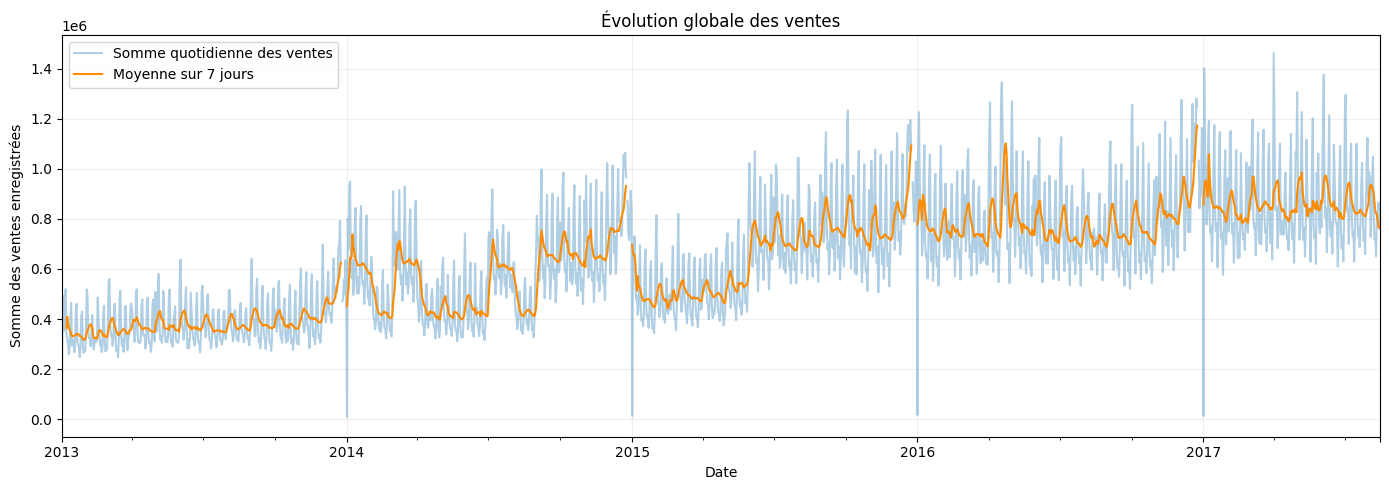

In [5]:
import matplotlib.pyplot as plt

# Additionner les ventes de tous les magasins et familles par jour
ventes_journalieres = (
    df.groupby("date")["sales"]
      .sum()
      .sort_index()
      .asfreq("D")
)

# Lisser les variations avec une moyenne sur 7 jours
moyenne_7j = ventes_journalieres.rolling(window=7).mean()

fig, ax = plt.subplots(figsize=(14, 5))

ventes_journalieres.plot(
    ax=ax, alpha=0.35, label="Somme quotidienne des ventes"
)

moyenne_7j.plot(
    ax=ax, color="darkorange", label="Moyenne sur 7 jours"
)

ax.set_title("Évolution globale des ventes")
ax.set_xlabel("Date")
ax.set_ylabel("Somme des ventes enregistrées")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.gcf().savefig(
    DOSSIER_FIGURES / "evolution_ventes.png", dpi=180, bbox_inches="tight"
)
plt.show()

In [6]:
# Garder les jours pour lesquels une valeur est disponible
jours_observes = ventes_journalieres.dropna()

# Afficher les 10 journées aux ventes les plus faibles
print("Les 10 journées aux ventes les plus faibles :")
display(
    jours_observes.nsmallest(10)
    .reset_index(name="somme_ventes")
)

# Afficher les 10 journées aux ventes les plus élevées
print("Les 10 journées aux ventes les plus élevées :")
display(
    jours_observes.nlargest(10)
    .reset_index(name="somme_ventes")
)

Les 10 journées aux ventes les plus faibles :


,date,somme_ventes
0,2013-01-01,2511.618999
1,2014-01-01,8602.065404
2,2017-01-01,12082.500997
3,2015-01-01,12773.616980
4,2016-01-01,16433.394000
5,2013-01-24,247245.690995
6,2013-03-14,247541.420096
7,2013-01-10,258982.003049
8,2013-01-29,264488.818076
9,2013-06-27,266525.458966


Les 10 journées aux ventes les plus élevées :


,date,somme_ventes
0,2017-04-01,1.463084e+06
1,2017-01-02,1.402306e+06
2,2017-06-04,1.376512e+06
3,2016-04-18,1.345921e+06
4,2017-05-01,1.306699e+06
5,2017-07-02,1.296379e+06
6,2016-12-23,1.282146e+06
7,2016-12-04,1.276195e+06
8,2016-04-17,1.271834e+06
9,2016-05-01,1.270121e+06


,ventes_moyennes,jours_observes
Lundi,764078.63,52
Mardi,711337.17,52
Mercredi,742917.90,52
Jeudi,626385.77,52
Vendredi,725051.07,53
Samedi,940911.69,53
Dimanche,1028099.69,51


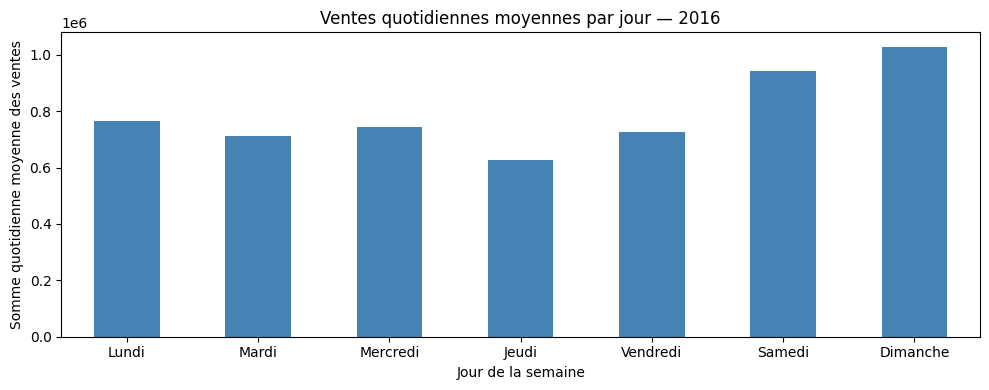

In [7]:
import matplotlib.pyplot as plt

# Sélectionner les ventes quotidiennes de 2016
ventes_2016 = ventes_journalieres.loc["2016"]

# Calculer la moyenne et le nombre de jours observés
bilan_jours = (
    ventes_2016.groupby(ventes_2016.index.dayofweek)
    .agg(["mean", "count"])
    .reindex(range(7))
)

bilan_jours.columns = ["ventes_moyennes", "jours_observes"]
bilan_jours.index = [
    "Lundi", "Mardi", "Mercredi", "Jeudi",
    "Vendredi", "Samedi", "Dimanche"
]

display(bilan_jours.round(2))

ax = bilan_jours["ventes_moyennes"].plot.bar(
    figsize=(10, 4), color="steelblue", rot=0
)
ax.set_title("Ventes quotidiennes moyennes par jour — 2016")
ax.set_xlabel("Jour de la semaine")
ax.set_ylabel("Somme quotidienne moyenne des ventes")

plt.tight_layout()
plt.gcf().savefig(
    DOSSIER_FIGURES / "saisonnalite_hebdomadaire.png", dpi=180, bbox_inches="tight"
)
plt.show()

## 4. Référence saisonnière et dernière fenêtre de validation

La dernière fenêtre va du **31 juillet au 15 août 2017**, soit **16 jours** et **28 512 lignes**. La référence est la moyenne des ventes des **huit semaines précédentes**, calculée par magasin, famille et jour de semaine. Les ventes de validation ne contribuent pas à cette moyenne.

Le RMSLE compare `log(1 + ventes réelles)` et `log(1 + prévisions)` ; plus il est faible, meilleur est le résultat. Les prévisions sont limitées à des valeurs positives ou nulles.

$$\mathrm{RMSLE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}\left[\log(1+y_i)-\log(1+\hat y_i)\right]^2}$$

In [8]:
import pandas as pd
import numpy as np

# 1. Réserver les 16 derniers jours pour la validation
debut_valid = df["date"].max() - pd.Timedelta(days=15)

train_df = df.loc[df["date"] < debut_valid].copy()
valid_df = df.loc[df["date"] >= debut_valid].copy()

# 2. Garder les 8 dernières semaines d'apprentissage
historique = train_df.loc[
    train_df["date"] >= debut_valid - pd.Timedelta(weeks=8)
].copy()

# 3. Identifier le jour de la semaine
historique["jour_semaine"] = historique["date"].dt.dayofweek
valid_df["jour_semaine"] = valid_df["date"].dt.dayofweek

# 4. Calculer les moyennes uniquement sur le passé
cles = ["store_nbr", "family", "jour_semaine"]

moyennes = (
    historique.groupby(cles, as_index=False)["sales"]
    .mean()
    .rename(columns={"sales": "prediction_baseline"})
)

# 5. Associer une prévision à chaque ligne de validation
valid_df = valid_df.merge(
    moyennes, on=cles, how="left", validate="many_to_one"
)

assert valid_df["prediction_baseline"].notna().all(), \
    "Certaines lignes n'ont pas de prévision."

# 6. Comparer les prévisions avec les ventes réelles
erreurs_log = (
    np.log1p(valid_df["sales"])
    - np.log1p(valid_df["prediction_baseline"])
)
rmsle = np.sqrt((erreurs_log ** 2).mean())

print("Début de validation :", debut_valid.date())
print("Nombre de lignes à prévoir :", len(valid_df))
print(f"RMSLE du modèle de référence : {rmsle:.4f}")

Début de validation : 2017-07-31
Nombre de lignes à prévoir : 28512
RMSLE du modèle de référence : 0.5206


## 5. LightGBM initial : variables et apprentissage

Les ventes décalées de **16, 21 et 28 jours** sont jointes par date exacte, magasin et famille. Le décalage minimal de 16 jours permet de prévoir toute la fenêtre sans utiliser ses ventes réelles. Les identifiants de magasin et de famille sont traités comme des catégories.

L'exploration utilise les 3 millions de lignes ; les modèles utilisent seulement les données préparées depuis le **31 juillet 2016**. Avant la dernière validation, l'apprentissage s'arrête au **30 juillet 2017**. Pour la soumission, le jeu préparé est étendu jusqu'au **15 août 2017**, soit **677 160 lignes**. Les jours supplémentaires précédant juillet 2016 sont utilisés uniquement pour calculer les variables historiques.

Le modèle apprend `log1p(sales)` avec une perte quadratique, cohérente avec l'évaluation RMSLE. Les paramètres sont fixés pour comparer les variantes.

In [9]:
import pandas as pd
import numpy as np

# Conserver le score du modèle de référence
rmsle_baseline = rmsle

# Utiliser un an d'apprentissage avant la validation
debut_modele = debut_valid - pd.Timedelta(days=365)
donnees = df.loc[df["date"] >= debut_modele].copy()

# Prendre uniquement des ventes antérieures à la validation
sources = df.loc[
    (df["date"] >= debut_modele - pd.Timedelta(days=28))
    & (df["date"] < debut_valid),
    ["date", "store_nbr", "family", "sales"]
].copy()

# Associer les ventes passées par date, magasin et famille
for retard in [16, 21, 28]:
    passe = sources.rename(
        columns={"sales": f"ventes_j{retard}"}
    ).copy()
    passe["date"] += pd.Timedelta(days=retard)

    donnees = donnees.merge(
        passe,
        on=["date", "store_nbr", "family"],
        how="left",
        validate="one_to_one"
    )

# Ajouter les informations du calendrier
donnees["jour_semaine"] = donnees["date"].dt.dayofweek
donnees["jour_mois"] = donnees["date"].dt.day
donnees["mois"] = donnees["date"].dt.month
donnees["temps"] = (donnees["date"] - debut_modele).dt.days

# Traiter les identifiants comme des catégories
for colonne in ["store_nbr", "family"]:
    donnees[colonne] = donnees[colonne].astype("category")

print("Données préparées :", donnees.shape)

Données préparées : (677160, 13)


In [10]:
from lightgbm import LGBMRegressor

variables = [
    "store_nbr", "family", "onpromotion",
    "jour_semaine", "jour_mois", "mois", "temps",
    "ventes_j16", "ventes_j21", "ventes_j28"
]

est_train = donnees["date"] < debut_valid

X_train = donnees.loc[est_train, variables]
y_train = np.log1p(donnees.loc[est_train, "sales"])

validation_lgbm = donnees.loc[~est_train].copy()

modele = LGBMRegressor(
    n_estimators=400,
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=50,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=2,
    verbosity=-1
)

# Apprendre à prévoir log(1 + ventes), cohérent avec le RMSLE
modele.fit(X_train, y_train)

# Revenir aux ventes et obtenir des prévisions positives ou nulles
predictions_log = modele.predict(validation_lgbm[variables])
validation_lgbm["prediction_lgbm"] = np.maximum(
    np.expm1(predictions_log), 0
)

# Évaluer sur les mêmes dates que le modèle de référence
erreurs_log = (
    np.log1p(validation_lgbm["sales"])
    - np.log1p(validation_lgbm["prediction_lgbm"])
)
rmsle_lgbm = np.sqrt((erreurs_log ** 2).mean())

comparaison = pd.DataFrame({
    "Modèle": ["Moyennes des 8 dernières semaines", "LightGBM"],
    "RMSLE": [rmsle_baseline, rmsle_lgbm]
})

display(comparaison.round(4))

,Modèle,RMSLE
0,Moyennes des 8 dernières semaines,0.5206
1,LightGBM,0.4180


### Diagnostic du modèle initial par famille

Le résultat **24 familles améliorées sur 33** ci-dessous concerne le **LightGBM initial**, comparé à la moyenne arithmétique, sur la seule dernière fenêtre. Ce nombre ne décrit pas le modèle enrichi retenu ensuite.

In [11]:
# Comparer les deux modèles sur exactement les mêmes lignes
evaluation = validation_lgbm[
    ["id", "date", "store_nbr", "family", "sales", "prediction_lgbm"]
].merge(
    valid_df[["id", "prediction_baseline"]],
    on="id",
    how="left",
    validate="one_to_one"
)

assert evaluation["prediction_baseline"].notna().all()

# Calculer les erreurs logarithmiques au carré
for nom in ["baseline", "lgbm"]:
    evaluation[f"erreur2_{nom}"] = (
        np.log1p(evaluation["sales"])
        - np.log1p(evaluation[f"prediction_{nom}"])
    ) ** 2

# Calculer le RMSLE de chaque modèle pour chaque famille
bilan_familles_initial = np.sqrt(
    evaluation.groupby("family", observed=True)[
        ["erreur2_baseline", "erreur2_lgbm"]
    ].mean()
)

bilan_familles_initial.columns = ["RMSLE_reference", "RMSLE_LightGBM"]

# Calculer la réduction relative du RMSLE
bilan_familles_initial["gain_pct"] = 100 * (
    1 - bilan_familles_initial["RMSLE_LightGBM"]
    / bilan_familles_initial["RMSLE_reference"].replace(0, np.nan)
)

print(
    "Familles améliorées :",
    (bilan_familles_initial["RMSLE_LightGBM"] < bilan_familles_initial["RMSLE_reference"]).sum(),
    "/", len(bilan_familles_initial)
)

# Afficher les 10 familles avec les gains les plus faibles
display(bilan_familles_initial.sort_values("gain_pct").head(10).round(4))

Familles améliorées : 24 / 33


,RMSLE_reference,RMSLE_LightGBM,gain_pct
family,,,
PRODUCE,0.1624,0.1909,-17.5368
EGGS,0.3196,0.3261,-2.0293
DELI,0.2113,0.2148,-1.6561
GROCERY II,0.6295,0.6396,-1.6037
LAWN AND GARDEN,0.4447,0.4503,-1.2686
PREPARED FOODS,0.2919,0.2956,-1.2562
PLAYERS AND ELECTRONICS,0.4787,0.4833,-0.9662
POULTRY,0.2287,0.2298,-0.4845
FROZEN FOODS,0.2973,0.2983,-0.3474


## 6. Validation sur trois origines successives

| Début | Fin | Horizon | Lignes |
|---|---|---:|---:|
| 2017-06-29 | 2017-07-14 | 16 jours | 28 512 |
| 2017-07-15 | 2017-07-30 | 16 jours | 28 512 |
| 2017-07-31 | 2017-08-15 | 16 jours | 28 512 |

Chaque modèle est entraîné sur les dates strictement antérieures à son origine. Les fenêtres de validation ne se chevauchent pas ; l'apprentissage s'étend à chaque origine. Les variables de ventes ont toutes un décalage d'au moins 16 jours, même lorsqu'elles sont précalculées dans une table commune. Le schéma ci-dessous représente ce protocole.

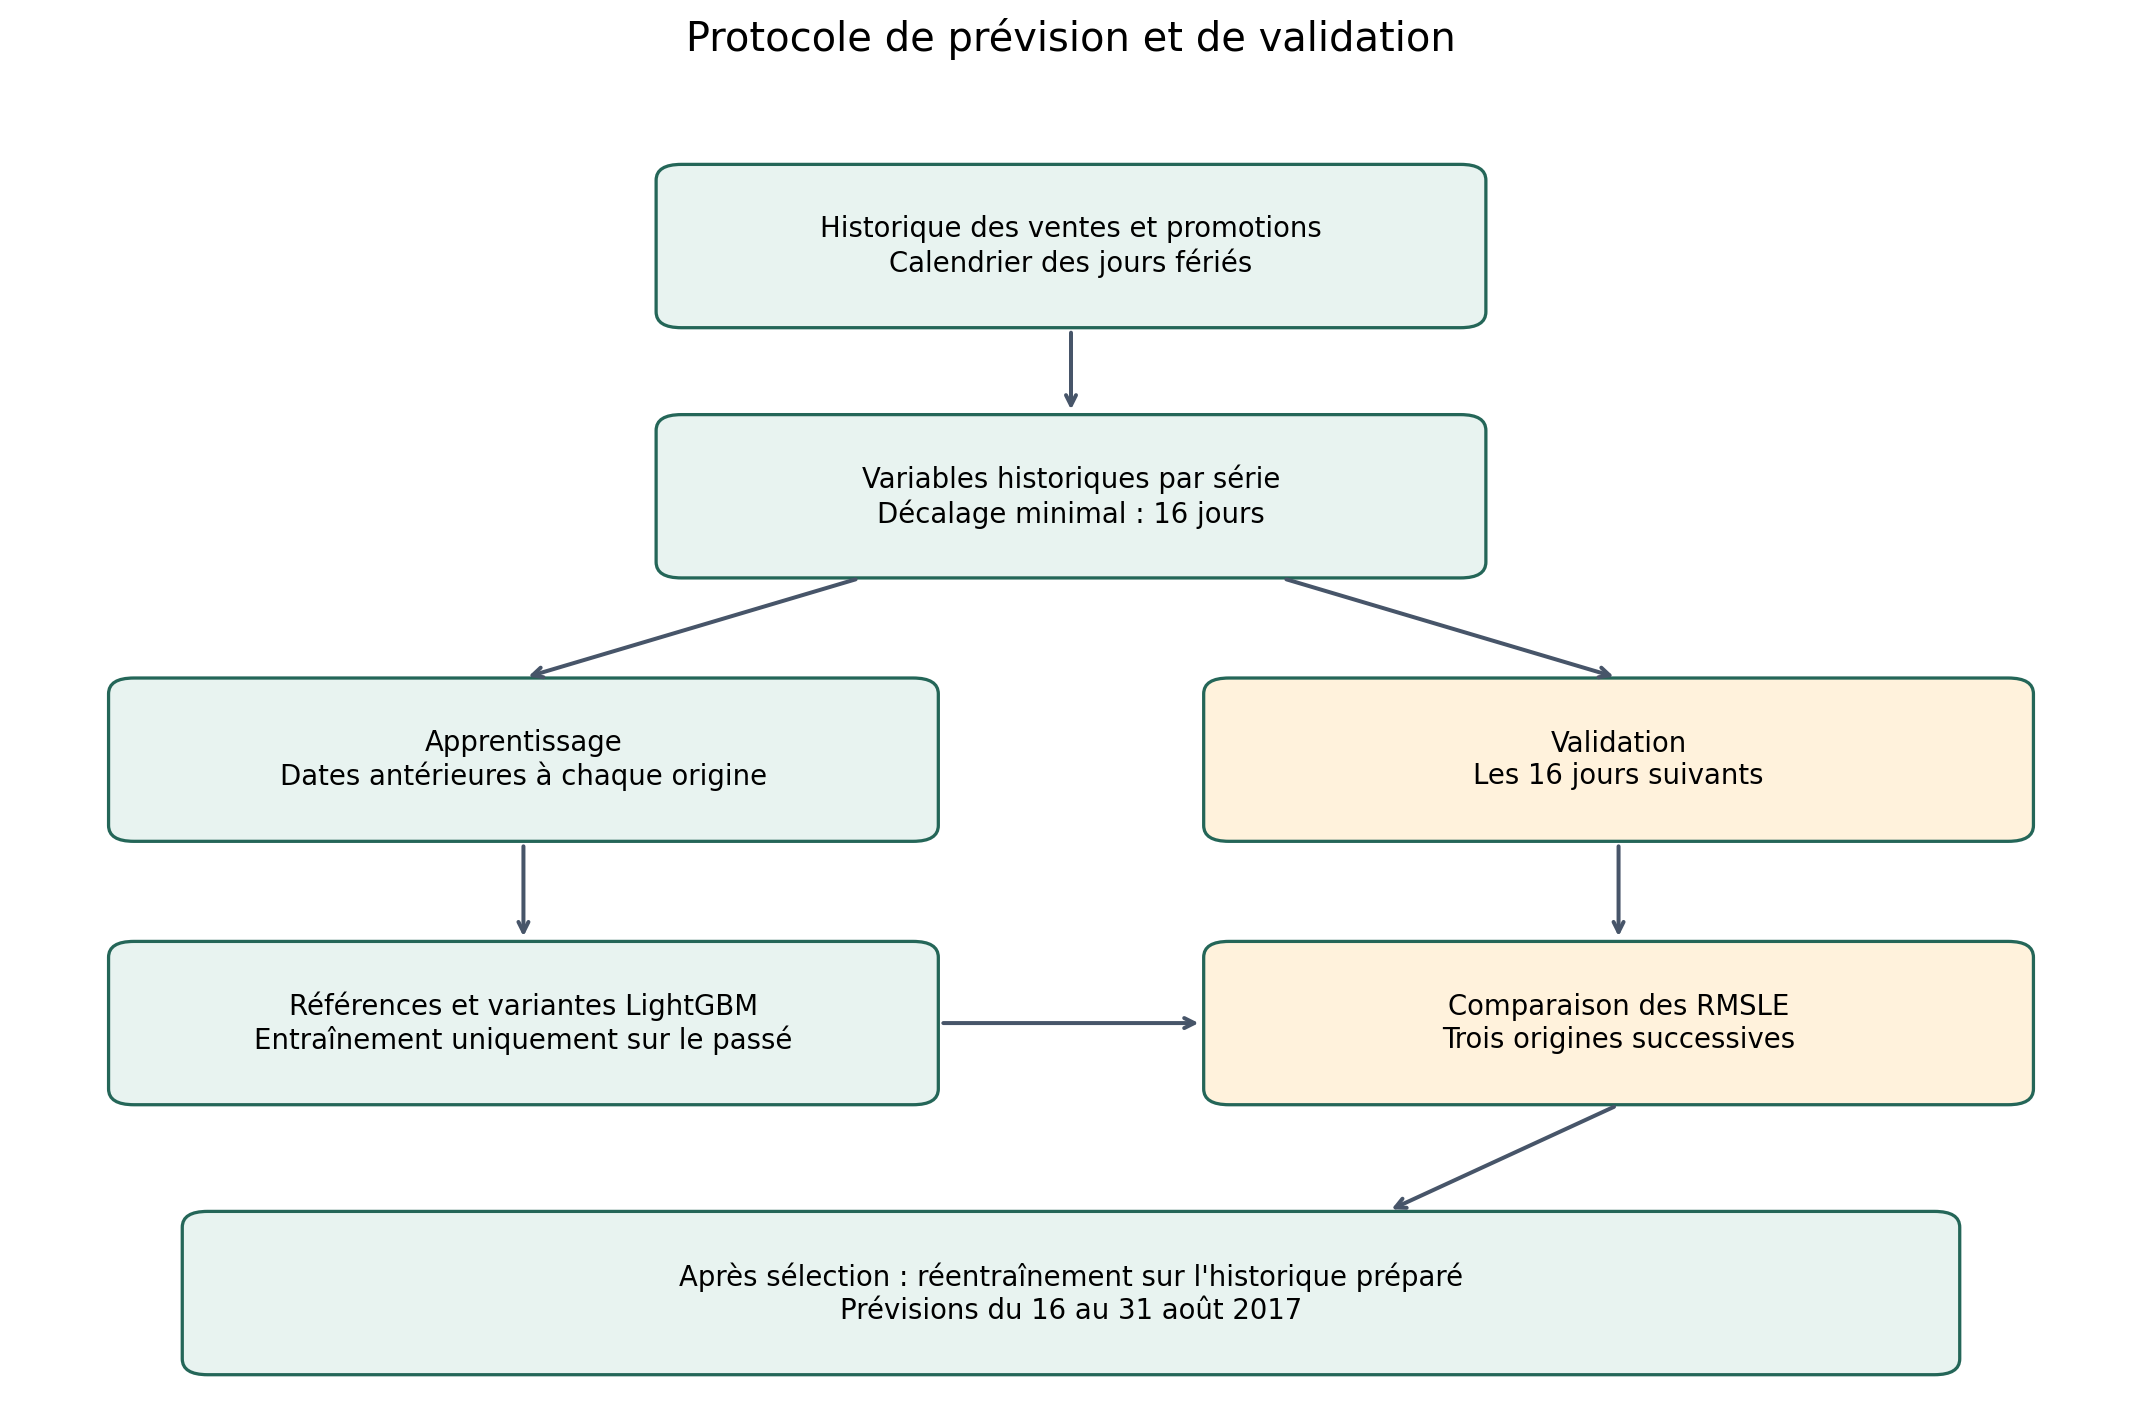

In [ ]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 8))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

def boite(x, y, texte, largeur=0.37, hauteur=0.10, couleur="#E8F3F0"):
    ax.add_patch(FancyBboxPatch(
        (x - largeur / 2, y - hauteur / 2), largeur, hauteur,
        boxstyle="round,pad=0.012", facecolor=couleur,
        edgecolor="#246658", linewidth=1.3
    ))
    ax.text(x, y, texte, ha="center", va="center", fontsize=11)

def fleche(depart, arrivee):
    ax.annotate("", xy=arrivee, xytext=depart,
                arrowprops={"arrowstyle": "->", "color": "#475569", "lw": 1.6})

boite(0.50, 0.88, "Historique des ventes et promotions\nCalendrier des jours fériés")
boite(0.50, 0.69, "Variables historiques par série\nDécalage minimal : 16 jours")
boite(0.24, 0.49, "Apprentissage\nDates antérieures à chaque origine")
boite(0.76, 0.49, "Validation\nLes 16 jours suivants", couleur="#FFF2DC")
boite(0.24, 0.29, "Références et variantes LightGBM\nEntraînement uniquement sur le passé")
boite(0.76, 0.29, "Comparaison des RMSLE\nTrois origines successives", couleur="#FFF2DC")
boite(0.50, 0.085, "Après sélection : réentraînement sur l'historique préparé\nPrévisions du 16 au 31 août 2017", largeur=0.82, hauteur=0.10)

fleche((0.50, 0.818), (0.50, 0.752))
fleche((0.40, 0.628), (0.24, 0.552))
fleche((0.60, 0.628), (0.76, 0.552))
fleche((0.24, 0.428), (0.24, 0.352))
fleche((0.76, 0.428), (0.76, 0.352))
fleche((0.437, 0.29), (0.563, 0.29))
fleche((0.76, 0.228), (0.65, 0.147))

ax.set_title("Protocole de prévision et de validation", fontsize=16, pad=15)
fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "schema_validation.png", dpi=180, bbox_inches="tight")
plt.show()

In [12]:
from lightgbm import LGBMRegressor
import pandas as pd
import numpy as np

def calculer_rmsle(reel, predit):
    return np.sqrt(
        np.mean((np.log1p(reel) - np.log1p(predit)) ** 2)
    )

resultats = []

# Deux nouvelles fenêtres, antérieures à notre première validation
debuts = [
    debut_valid - pd.Timedelta(days=32),
    debut_valid - pd.Timedelta(days=16)
]

for debut in debuts:
    fin = debut + pd.Timedelta(days=15)

    # 1. Séparer le passé et les 16 jours à prévoir
    train_periode = donnees.loc[donnees["date"] < debut]
    val_periode = donnees.loc[
        donnees["date"].between(debut, fin)
    ].copy()

    # 2. Réentraîner LightGBM avec les mêmes réglages
    modele_periode = LGBMRegressor(**modele.get_params())
    modele_periode.fit(
        train_periode[variables],
        np.log1p(train_periode["sales"])
    )

    val_periode["prediction_lgbm"] = np.maximum(
        np.expm1(modele_periode.predict(val_periode[variables])),
        0
    )

    # 3. Recalculer la référence sur les 8 semaines précédentes
    historique_periode = df.loc[
        (df["date"] >= debut - pd.Timedelta(weeks=8))
        & (df["date"] < debut)
    ].copy()

    historique_periode["jour_semaine"] = (
        historique_periode["date"].dt.dayofweek
    )

    cles = ["store_nbr", "family", "jour_semaine"]
    moyennes_periode = (
        historique_periode.groupby(cles, as_index=False)["sales"]
        .mean()
        .rename(columns={"sales": "prediction_baseline"})
    )

    val_periode = val_periode.merge(
        moyennes_periode,
        on=cles,
        how="left",
        validate="many_to_one"
    )

    assert val_periode["prediction_baseline"].notna().all()

    # 4. Comparer les erreurs sur cette période
    resultats.append({
        "debut": debut.date(),
        "fin": fin.date(),
        "nombre_previsions": len(val_periode),
        "RMSLE_reference": calculer_rmsle(
            val_periode["sales"], val_periode["prediction_baseline"]
        ),
        "RMSLE_LightGBM": calculer_rmsle(
            val_periode["sales"], val_periode["prediction_lgbm"]
        )
    })

    print("Période terminée :", debut.date(), "→", fin.date())

# Ajouter les résultats déjà obtenus sur la dernière fenêtre
resultats.append({
    "debut": debut_valid.date(),
    "fin": (debut_valid + pd.Timedelta(days=15)).date(),
    "nombre_previsions": len(valid_df),
    "RMSLE_reference": rmsle_baseline,
    "RMSLE_LightGBM": rmsle_lgbm
})

backtest = pd.DataFrame(resultats).sort_values("debut")
backtest["gain_pct"] = 100 * (
    1 - backtest["RMSLE_LightGBM"] / backtest["RMSLE_reference"]
)

display(backtest.round(4))

Période terminée : 2017-06-29 → 2017-07-14
Période terminée : 2017-07-15 → 2017-07-30


,debut,fin,nombre_previsions,RMSLE_reference,RMSLE_LightGBM,gain_pct
0,2017-06-29,2017-07-14,28512,0.4325,0.3984,7.8858
1,2017-07-15,2017-07-30,28512,0.4338,0.4038,6.9126
2,2017-07-31,2017-08-15,28512,0.5206,0.4180,19.7099


### Vérifier les dates et identifiants du jeu de test

Les dates présentes dans les fichiers, du 16 au 31 août 2017 inclus, déterminent l’horizon de 16 jours.

In [13]:
from pathlib import Path

dossier = Path(chemin).parent

test = pd.read_csv(
    dossier / "test.csv",
    parse_dates=["date"]
)
exemple = pd.read_csv(dossier / "sample_submission.csv")

print(
    "Période à prévoir :",
    test["date"].min().date(), "→", test["date"].max().date()
)
print("Nombre de prévisions :", len(test))

# Vérifier que les dates sont futures et compatibles avec nos retards
assert test["date"].min() > df["date"].max()
assert (test["date"].max() - df["date"].max()).days <= 16

# Vérifier les identifiants attendus
assert test["id"].is_unique and exemple["id"].is_unique
assert set(test["id"]) == set(exemple["id"])

Période à prévoir : 2017-08-16 → 2017-08-31
Nombre de prévisions : 28512


### Première soumission : modèle initial

Cette étape historique produit `submission.csv` avec le **LightGBM initial**. La soumission du modèle retenu est créée en fin de notebook sous **`submission_amelioree.csv`**.

In [14]:
# Préparer les mêmes variables que pendant la validation
test_features = test.copy()

sources_test = df.loc[
    df["date"] >= test["date"].min() - pd.Timedelta(days=28),
    ["date", "store_nbr", "family", "sales"]
].copy()

for retard in [16, 21, 28]:
    passe = sources_test.rename(
        columns={"sales": f"ventes_j{retard}"}
    ).copy()
    passe["date"] += pd.Timedelta(days=retard)

    test_features = test_features.merge(
        passe,
        on=["date", "store_nbr", "family"],
        how="left",
        validate="one_to_one"
    )

test_features["jour_semaine"] = test_features["date"].dt.dayofweek
test_features["jour_mois"] = test_features["date"].dt.day
test_features["mois"] = test_features["date"].dt.month
test_features["temps"] = (
    test_features["date"] - debut_modele
).dt.days

# Utiliser les catégories de notre jeu d'apprentissage
for colonne in ["store_nbr", "family"]:
    test_features[colonne] = test_features[colonne].astype(
        donnees[colonne].dtype
    )

# Réentraîner avec toutes les lignes de notre historique préparé
modele_final = LGBMRegressor(**modele.get_params())
modele_final.fit(
    donnees[variables],
    np.log1p(donnees["sales"])
)

# Prévoir les ventes
predictions = np.maximum(
    np.expm1(modele_final.predict(test_features[variables])),
    0
)

# Respecter l'ordre des identifiants du fichier exemple
predictions_par_id = pd.DataFrame({
    "id": test_features["id"],
    "sales": predictions
})

soumission = exemple[["id"]].merge(
    predictions_par_id,
    on="id",
    how="left",
    validate="one_to_one"
)

assert np.isfinite(soumission["sales"]).all()

# Enregistrer le fichier dans l'espace de travail Kaggle
fichier_initial = DOSSIER_SORTIE / "submission.csv"
soumission.to_csv(fichier_initial, index=False)

print("Fichier créé :", fichier_initial)
print("Nombre de lignes :", len(soumission))
display(soumission.head())

Fichier créé : /kaggle/working/submission.csv
Nombre de lignes : 28512


,id,sales
0,3000888,3.930347
1,3000889,0.026045
2,3000890,4.341914
3,3000891,2222.281616
4,3000892,0.181866


### Exemples de prévisions du modèle initial

Ces courbes illustrent le diagnostic ayant conduit à examiner le calendrier. Elles ne représentent pas le modèle enrichi des statistiques historiques.

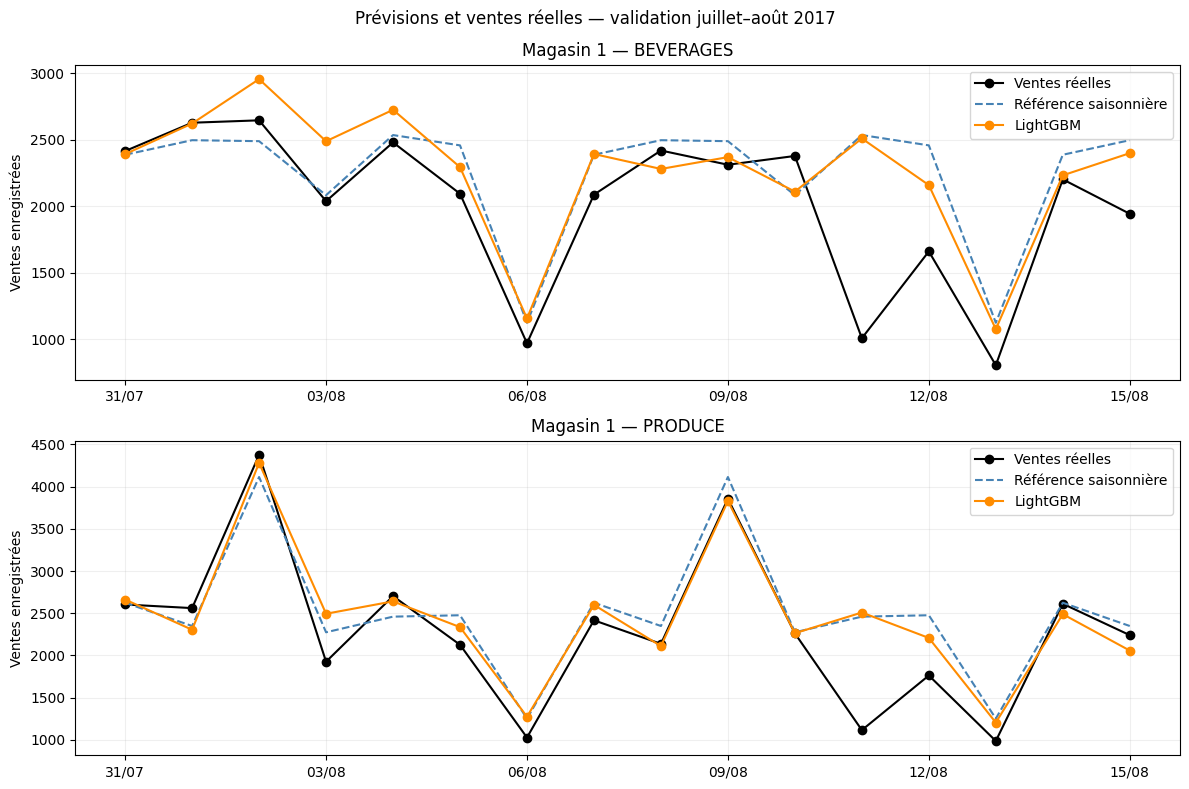

In [15]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Deux exemples fixes dans le magasin 1
for ax, famille in zip(axes, ["BEVERAGES", "PRODUCE"]):
    courbe = evaluation.loc[
        (evaluation["store_nbr"] == 1)
        & (evaluation["family"] == famille)
    ].sort_values("date")

    ax.plot(
        courbe["date"], courbe["sales"],
        "o-", label="Ventes réelles", color="black"
    )
    ax.plot(
        courbe["date"], courbe["prediction_baseline"],
        "--", label="Référence saisonnière", color="steelblue"
    )
    ax.plot(
        courbe["date"], courbe["prediction_lgbm"],
        "o-", label="LightGBM", color="darkorange"
    )

    ax.set_title(f"Magasin 1 — {famille}")
    ax.set_ylabel("Ventes enregistrées")
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle("Prévisions et ventes réelles — validation juillet–août 2017")
plt.tight_layout()
plt.gcf().savefig(
    DOSSIER_FIGURES / "previsions_initiales.png", dpi=180, bbox_inches="tight"
)
plt.show()

## Interprétation des prévisions

La comparaison concerne le magasin 1, pour les familles BEVERAGES et PRODUCE, du 31 juillet au 15 août 2017.

Les deux méthodes reproduisent une partie des variations, notamment les creux des 6 et 13 août. Elles surestiment cependant fortement les ventes du 11 août. Cette erreur commune conduit à examiner les jours fériés, leurs éventuels reports et les caractéristiques du magasin.

Ces deux exemples complètent les scores calculés sur l’ensemble des 54 magasins ; ils ne résument pas à eux seuls la performance globale.

## 7. Examiner puis ajouter les jours fériés nationaux

La localisation du magasin sert au diagnostic. Seuls les événements nationaux planifiés et effectivement observés sont utilisés comme variables. Un jour marqué `transferred=True` n’est pas traité comme férié ; la date de type `Transfer` porte le report. Les événements imprévus ainsi que les jours fériés locaux et régionaux ne sont pas inclus dans cette variante.

In [16]:
import pandas as pd
from pathlib import Path

# Charger le calendrier et les informations des magasins
chemin_feries = dossier / "holidays_events.csv"

feries = pd.read_csv(chemin_feries, parse_dates=["date"])
magasins = pd.read_csv(chemin_feries.parent / "stores.csv")

# Identifier la localisation et le type du magasin 1
print("Informations sur le magasin 1 :")
display(magasins.loc[magasins["store_nbr"] == 1])

# Examiner les événements autour de la baisse observée
print("Calendrier du 9 au 13 août 2017 :")
display(
    feries.loc[
        feries["date"].between("2017-08-09", "2017-08-13")
    ].sort_values("date")
)

Informations sur le magasin 1 :


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13


Calendrier du 9 au 13 août 2017 :


,date,type,locale,locale_name,description,transferred
324,2017-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True
325,2017-08-11,Transfer,National,Ecuador,Traslado Primer Grito de Independencia,False


In [17]:
from lightgbm import LGBMRegressor
import pandas as pd
import numpy as np

# 1. Sélectionner les jours fériés nationaux effectivement observés
calendrier_actif = feries.loc[
    feries["locale"].eq("National")
    & feries["transferred"].eq(False)
    & feries["type"].isin([
        "Holiday", "Transfer", "Additional", "Bridge"
    ])
]

dates_feriees = calendrier_actif["date"].drop_duplicates()

# 2. Ajouter un indicateur sans multiplier les lignes
donnees_calendrier = donnees.copy()
donnees_calendrier["ferie_national"] = (
    donnees_calendrier["date"]
    .isin(dates_feriees)
    .astype("int8")
)

variables_calendrier = variables + ["ferie_national"]

# 3. Reprendre exactement la même séparation chronologique
est_train = donnees_calendrier["date"] < debut_valid
validation_calendrier = donnees_calendrier.loc[~est_train].copy()

# 4. Entraîner un nouveau modèle avec les mêmes réglages
modele_calendrier = LGBMRegressor(**modele.get_params())
modele_calendrier.fit(
    donnees_calendrier.loc[est_train, variables_calendrier],
    np.log1p(donnees_calendrier.loc[est_train, "sales"])
)

# 5. Prévoir les ventes sur la validation
validation_calendrier["prediction_calendrier"] = np.maximum(
    np.expm1(
        modele_calendrier.predict(
            validation_calendrier[variables_calendrier]
        )
    ),
    0
)

# 6. Calculer l'erreur
erreurs_log = (
    np.log1p(validation_calendrier["sales"])
    - np.log1p(validation_calendrier["prediction_calendrier"])
)
rmsle_calendrier = np.sqrt((erreurs_log ** 2).mean())

# 7. Comparer les trois approches
comparaison_calendrier = pd.DataFrame({
    "Modèle": [
        "Référence saisonnière",
        "LightGBM initial",
        "LightGBM + jours fériés nationaux"
    ],
    "RMSLE": [
        rmsle_baseline,
        rmsle_lgbm,
        rmsle_calendrier
    ]
})

display(comparaison_calendrier.round(4))

,Modèle,RMSLE
0,Référence saisonnière,0.5206
1,LightGBM initial,0.4180
2,LightGBM + jours fériés nationaux,0.4155


### Effet du calendrier sur les deux exemples

Comparaison du modèle initial et de la variante avec calendrier, avant l’ajout des statistiques historiques. La baisse du 11 août coïncide avec le jour férié transféré ; ce constat ne prouve pas un effet causal.

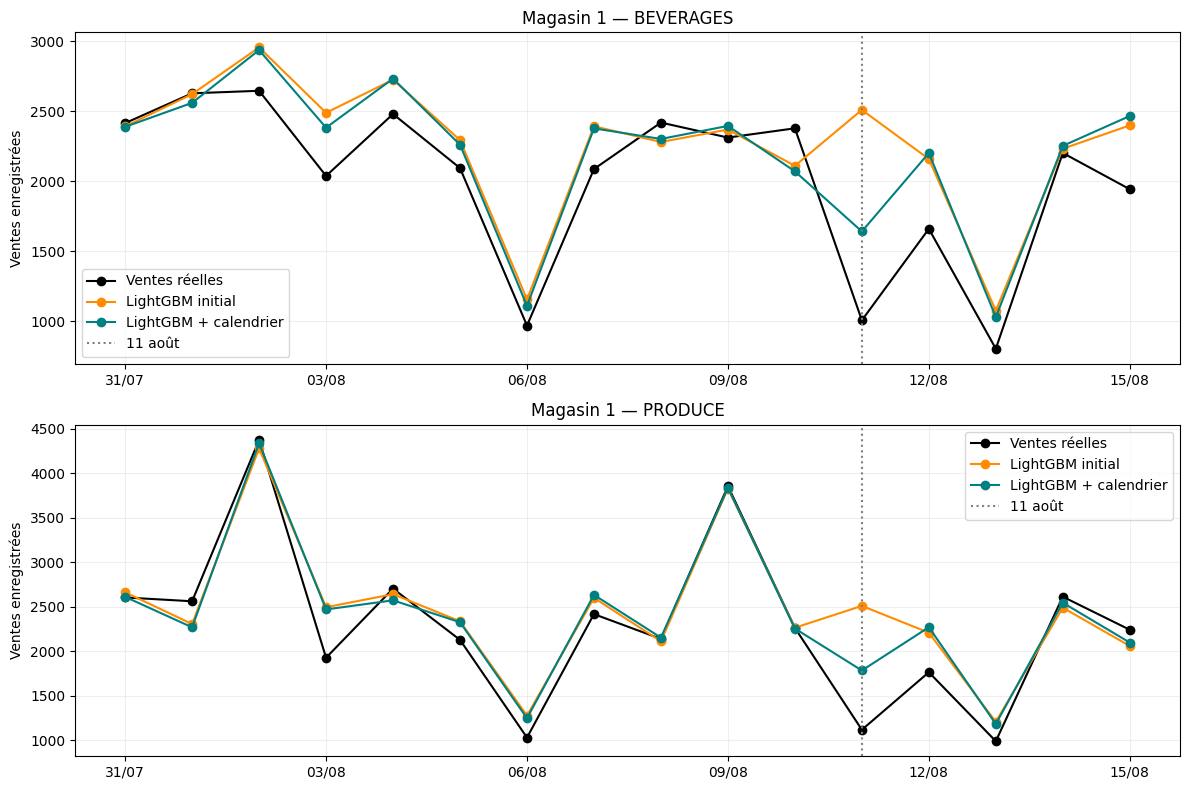

In [18]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

diagnostic_cal = evaluation.merge(
    validation_calendrier[["id", "prediction_calendrier"]],
    on="id",
    how="left",
    validate="one_to_one"
)

assert diagnostic_cal["prediction_calendrier"].notna().all()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

for ax, famille in zip(axes, ["BEVERAGES", "PRODUCE"]):
    courbe = diagnostic_cal.loc[
        (diagnostic_cal["store_nbr"] == 1)
        & (diagnostic_cal["family"] == famille)
    ].sort_values("date")

    for colonne, label, couleur in [
        ("sales", "Ventes réelles", "black"),
        ("prediction_lgbm", "LightGBM initial", "darkorange"),
        ("prediction_calendrier", "LightGBM + calendrier", "teal")
    ]:
        ax.plot(
            courbe["date"], courbe[colonne],
            marker="o", label=label, color=couleur
        )

    ax.axvline(
        pd.Timestamp("2017-08-11"),
        color="gray", linestyle=":", label="11 août"
    )
    ax.set_title(f"Magasin 1 — {famille}")
    ax.set_ylabel("Ventes enregistrées")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.gcf().savefig(
    DOSSIER_FIGURES / "effet_calendrier.png", dpi=180, bbox_inches="tight"
)
plt.show()

### Vérifier le calendrier sur les trois fenêtres

Le gain est faible et ne se retrouve pas dans chacune des trois fenêtres. Cette variante reste une étape de comparaison, sans conclusion générale sur l’effet des jours fériés.

In [19]:
scores_calendrier = []

for _, periode in backtest.iterrows():
    debut = pd.Timestamp(periode["debut"])
    fin = pd.Timestamp(periode["fin"])

    if debut == debut_valid:
        score = rmsle_calendrier

    else:
        est_train = donnees_calendrier["date"] < debut
        val_temp = donnees_calendrier.loc[
            donnees_calendrier["date"].between(debut, fin)
        ].copy()

        modele_temp = LGBMRegressor(
            **modele_calendrier.get_params()
        )
        modele_temp.fit(
            donnees_calendrier.loc[est_train, variables_calendrier],
            np.log1p(donnees_calendrier.loc[est_train, "sales"])
        )

        predictions_temp = np.maximum(
            np.expm1(
                modele_temp.predict(val_temp[variables_calendrier])
            ),
            0
        )

        score = np.sqrt(np.mean(
            (
                np.log1p(val_temp["sales"].to_numpy())
                - np.log1p(predictions_temp)
            ) ** 2
        ))

    scores_calendrier.append(score)
    print("Période terminée :", debut.date(), "→", fin.date())

backtest_calendrier = backtest[
    ["debut", "fin", "RMSLE_reference", "RMSLE_LightGBM"]
].copy()

backtest_calendrier["RMSLE_calendrier"] = scores_calendrier

backtest_calendrier["gain_vs_initial_pct"] = 100 * (
    1
    - backtest_calendrier["RMSLE_calendrier"]
    / backtest_calendrier["RMSLE_LightGBM"]
)

display(backtest_calendrier.round(4))

Période terminée : 2017-06-29 → 2017-07-14
Période terminée : 2017-07-15 → 2017-07-30
Période terminée : 2017-07-31 → 2017-08-15


,debut,fin,RMSLE_reference,RMSLE_LightGBM,RMSLE_calendrier,gain_vs_initial_pct
0,2017-06-29,2017-07-14,0.4325,0.3984,0.3990,-0.1466
1,2017-07-15,2017-07-30,0.4338,0.4038,0.4042,-0.0874
2,2017-07-31,2017-08-15,0.5206,0.4180,0.4155,0.5952


## 8. Ajouter une référence logarithmique

La seconde référence calcule la moyenne de `log1p(sales)` sur les huit semaines précédentes, par magasin, famille et jour de semaine. Elle évite d’attribuer à LightGBM tout le bénéfice du changement d’échelle. Le RMSLE regroupé est la **racine de la moyenne pondérée des RMSLE au carré**, pondérée par le nombre de prévisions ; les trois périodes ont ici le même effectif.

Résultats par fenêtre :


,debut,fin,RMSLE_reference,RMSLE_reference_log,RMSLE_LightGBM,RMSLE_calendrier
0,2017-06-29,2017-07-14,0.4325,0.4059,0.3984,0.3990
1,2017-07-15,2017-07-30,0.4338,0.4170,0.4038,0.4042
2,2017-07-31,2017-08-15,0.5206,0.5286,0.4180,0.4155


Résultats regroupés :


,Modele,RMSLE_regroupe
3,LightGBM + calendrier,0.4063
2,LightGBM,0.4068
1,Moyenne logarithmique,0.4539
0,Moyenne simple,0.4641


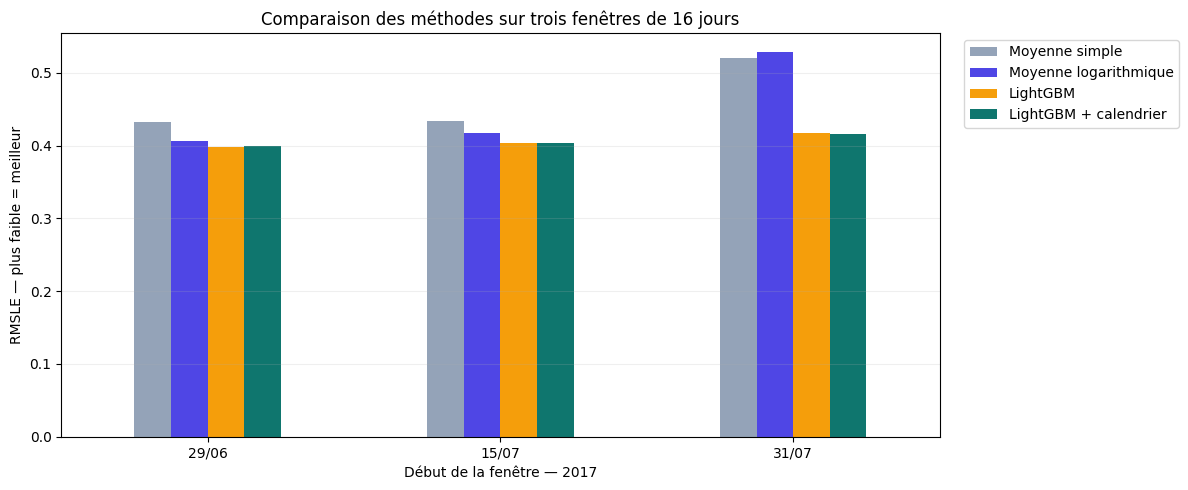

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

comparaison_modeles = backtest_calendrier[
    ["debut", "fin", "RMSLE_reference",
     "RMSLE_LightGBM", "RMSLE_calendrier"]
].copy()

scores_log = []
effectifs = []
cles = ["store_nbr", "family", "jour_semaine"]

for _, periode in comparaison_modeles.iterrows():
    debut = pd.Timestamp(periode["debut"])
    fin = pd.Timestamp(periode["fin"])

    # Apprendre uniquement sur les 8 semaines précédentes
    hist_log = df.loc[
        (df["date"] >= debut - pd.Timedelta(weeks=8))
        & (df["date"] < debut)
    ].copy()

    hist_log["jour_semaine"] = hist_log["date"].dt.dayofweek
    hist_log["log_ventes"] = np.log1p(hist_log["sales"])

    profil_log = (
        hist_log.groupby(cles, as_index=False)["log_ventes"]
        .mean()
        .rename(columns={"log_ventes": "prediction_log"})
    )

    # Prévoir les 16 jours avec ces moyennes historiques
    val_log = df.loc[df["date"].between(debut, fin)].copy()
    val_log["jour_semaine"] = val_log["date"].dt.dayofweek

    val_log = val_log.merge(
        profil_log, on=cles, how="left", validate="many_to_one"
    )

    assert val_log["prediction_log"].notna().all()

    score = np.sqrt(np.mean(
        (np.log1p(val_log["sales"]) - val_log["prediction_log"]) ** 2
    ))

    scores_log.append(score)
    effectifs.append(len(val_log))

comparaison_modeles["RMSLE_reference_log"] = scores_log

colonnes = [
    "RMSLE_reference", "RMSLE_reference_log",
    "RMSLE_LightGBM", "RMSLE_calendrier"
]
noms = [
    "Moyenne simple", "Moyenne logarithmique",
    "LightGBM", "LightGBM + calendrier"
]

print("Résultats par fenêtre :")
display(
    comparaison_modeles[["debut", "fin"] + colonnes].round(4)
)

# Regrouper les erreurs en tenant compte du nombre de prévisions
scores_regroupes = np.sqrt(np.average(
    comparaison_modeles[colonnes].to_numpy() ** 2,
    axis=0,
    weights=effectifs
))

resume_modeles = pd.DataFrame({
    "Modele": noms,
    "RMSLE_regroupe": scores_regroupes
}).sort_values("RMSLE_regroupe")

print("Résultats regroupés :")
display(resume_modeles.round(4))

# Ajouter un graphique comparatif au notebook
graphique = comparaison_modeles[colonnes].copy()
graphique.columns = noms
graphique.index = pd.to_datetime(
    comparaison_modeles["debut"]
).dt.strftime("%d/%m")

ax = graphique.plot.bar(
    figsize=(12, 5),
    rot=0,
    color=["#94a3b8", "#4f46e5", "#f59e0b", "#0f766e"]
)
ax.set_title("Comparaison des méthodes sur trois fenêtres de 16 jours")
ax.set_xlabel("Début de la fenêtre — 2017")
ax.set_ylabel("RMSLE — plus faible = meilleur")
ax.set_ylim(bottom=0)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.gcf().savefig(
    DOSSIER_FIGURES / "comparaison_intermediaire.png", dpi=180, bbox_inches="tight"
)
plt.show()

## 9. Ajouter des statistiques historiques disponibles à l'origine

Pour une cible de date **J**, les moyennes sont calculées après un décalage de 16 jours :

| Variable | Dates de ventes utilisées | Observations minimales |
|---|---|---:|
| Moyenne sur 7 jours | J−22 à J−16 inclus | 4 |
| Moyenne sur 28 jours | J−43 à J−16 inclus | 14 |
| Écart-type sur 28 jours | J−43 à J−16 inclus | 14 |

La grille quotidienne contient les dates absentes, notamment les 25 décembre. Elles restent inconnues (`NaN`) et ne sont pas remplacées par zéro. Le décalage représente ainsi des jours calendaires, et non un nombre de lignes observées.

In [21]:
import pandas as pd
import numpy as np
from lightgbm import LGBMRegressor

def ajouter_stats_ventes(lignes, historique):
    cles = ["store_nbr", "family", "date"]
    statistiques = [
        "moyenne_7j", "moyenne_28j", "ecart_type_28j"
    ]

    # Prévoir suffisamment de jours pour les fenêtres historiques
    dates = pd.date_range(
        lignes["date"].min() - pd.Timedelta(days=16 + 28 - 1),
        lignes["date"].max()
    )

    # Construire un calendrier quotidien pour chaque série
    index = pd.MultiIndex.from_product([
        lignes["store_nbr"].drop_duplicates().to_numpy(),
        lignes["family"].drop_duplicates().to_numpy(),
        dates
    ], names=cles)

    grille = historique.loc[
        historique["date"].between(dates.min(), dates.max()),
        cles + ["sales"]
    ].set_index(cles).reindex(index)

    # Décaler avant de calculer les statistiques
    grille["ventes_disponibles"] = grille.groupby(
        level=["store_nbr", "family"], sort=False
    )["sales"].shift(16)

    groupes = grille.groupby(
        level=["store_nbr", "family"], sort=False
    )["ventes_disponibles"]

    grille["moyenne_7j"] = groupes.transform(
        lambda s: s.rolling(7, min_periods=4).mean()
    )
    grille["moyenne_28j"] = groupes.transform(
        lambda s: s.rolling(28, min_periods=14).mean()
    )
    grille["ecart_type_28j"] = groupes.transform(
        lambda s: s.rolling(28, min_periods=14).std()
    )

    resultat = lignes.merge(
        grille[statistiques].reset_index(),
        on=cles,
        how="left",
        validate="one_to_one"
    )

    # Conserver les types des catégories après la jointure
    for colonne in ["store_nbr", "family"]:
        resultat[colonne] = resultat[colonne].astype(
            lignes[colonne].dtype
        )

    return resultat

donnees_stats = ajouter_stats_ventes(donnees_calendrier, df)

variables_stats = variables_calendrier + [
    "moyenne_7j", "moyenne_28j", "ecart_type_28j"
]

print("Nouvelles variables préparées.")

Nouvelles variables préparées.


### Évaluer le modèle enrichi avec les mêmes fenêtres

Les réglages de LightGBM et les périodes sont conservés. Seules les trois nouvelles variables sont ajoutées à la variante avec calendrier.

In [22]:
scores_stats = []
effectifs_stats = []

for _, periode in comparaison_modeles.iterrows():
    debut = pd.Timestamp(periode["debut"])
    fin = pd.Timestamp(periode["fin"])

    apprentissage = donnees_stats["date"] < debut
    val_stats = donnees_stats.loc[
        donnees_stats["date"].between(debut, fin)
    ].copy()

    modele_periode_stats = LGBMRegressor(
        **modele_calendrier.get_params()
    )
    modele_periode_stats.fit(
        donnees_stats.loc[apprentissage, variables_stats],
        np.log1p(donnees_stats.loc[apprentissage, "sales"])
    )

    val_stats["prediction_stats"] = np.maximum(
        np.expm1(
            modele_periode_stats.predict(val_stats[variables_stats])
        ),
        0
    )

    score = np.sqrt(np.mean(
        (
            np.log1p(val_stats["sales"])
            - np.log1p(val_stats["prediction_stats"])
        ) ** 2
    ))

    scores_stats.append(score)
    effectifs_stats.append(len(val_stats))

    # Conserver les prévisions de la dernière fenêtre pour les graphiques
    if debut == debut_valid:
        modele_stats = modele_periode_stats
        validation_stats = val_stats.copy()

    print("Période terminée :", debut.date(), "→", fin.date())

comparaison_stats = comparaison_modeles.copy()
comparaison_stats["RMSLE_stats"] = scores_stats

colonnes_stats = [
    "RMSLE_reference", "RMSLE_reference_log",
    "RMSLE_LightGBM", "RMSLE_calendrier", "RMSLE_stats"
]

display(
    comparaison_stats[["debut", "fin"] + colonnes_stats].round(4)
)

resume_stats = pd.DataFrame({
    "Modele": [
        "Moyenne simple",
        "Moyenne logarithmique",
        "LightGBM",
        "LightGBM + calendrier",
        "LightGBM + calendrier + statistiques"
    ],
    "RMSLE_regroupe": np.sqrt(np.average(
        comparaison_stats[colonnes_stats].to_numpy() ** 2,
        axis=0,
        weights=effectifs_stats
    ))
}).sort_values("RMSLE_regroupe")

display(resume_stats.round(4))

Période terminée : 2017-06-29 → 2017-07-14
Période terminée : 2017-07-15 → 2017-07-30
Période terminée : 2017-07-31 → 2017-08-15


,debut,fin,RMSLE_reference,RMSLE_reference_log,RMSLE_LightGBM,RMSLE_calendrier,RMSLE_stats
0,2017-06-29,2017-07-14,0.4325,0.4059,0.3984,0.3990,0.3859
1,2017-07-15,2017-07-30,0.4338,0.4170,0.4038,0.4042,0.3954
2,2017-07-31,2017-08-15,0.5206,0.5286,0.4180,0.4155,0.4100


,Modele,RMSLE_regroupe
4,LightGBM + calendrier + statistiques,0.3972
3,LightGBM + calendrier,0.4063
2,LightGBM,0.4068
1,Moyenne logarithmique,0.4539
0,Moyenne simple,0.4641


## 10. Comparaison finale et importance des variables

La figure de performance porte sur les trois fenêtres. L’importance par **gain** porte sur le modèle entraîné avant le 31 juillet 2017. Les moyennes à 7 et 28 jours représentent environ **80,6 %** et **12,8 %** du gain total enregistré. Ces parts décrivent les coupures des arbres ; elles ne mesurent pas un impact causal, et les variables historiques sont corrélées.

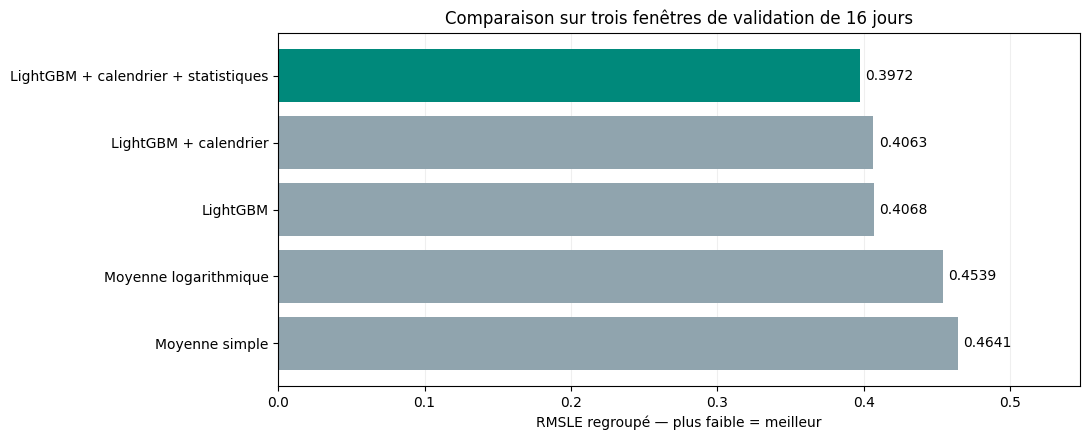

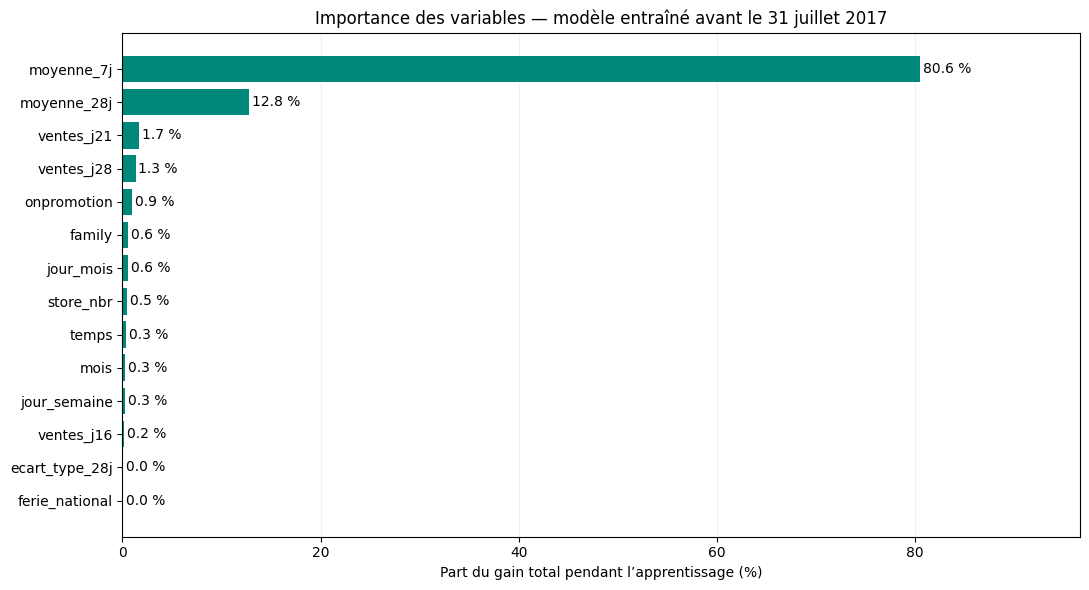

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Comparaison des cinq méthodes
comparatif = resume_stats.sort_values(
    "RMSLE_regroupe", ascending=False
).copy()

couleurs = [
    "#00897B" if nom == "LightGBM + calendrier + statistiques"
    else "#90A4AE"
    for nom in comparatif["Modele"]
]

fig, ax = plt.subplots(figsize=(11, 4.5))

ax.barh(
    comparatif["Modele"],
    comparatif["RMSLE_regroupe"],
    color=couleurs
)

for position, score in enumerate(comparatif["RMSLE_regroupe"]):
    ax.text(
        score + 0.004, position,
        f"{score:.4f}", va="center"
    )

ax.set_xlim(0, comparatif["RMSLE_regroupe"].max() * 1.18)
ax.set_xlabel("RMSLE regroupé — plus faible = meilleur")
ax.set_title("Comparaison sur trois fenêtres de validation de 16 jours")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(
    DOSSIER_FIGURES / "comparaison_modeles.png",
    dpi=180, bbox_inches="tight"
)
plt.show()


# 2. Importance des variables du modèle de la dernière fenêtre
importance_stats = pd.DataFrame({
    "variable": modele_stats.booster_.feature_name(),
    "gain": modele_stats.booster_.feature_importance(
        importance_type="gain"
    )
})

importance_stats["gain_pct"] = (
    100 * importance_stats["gain"] / importance_stats["gain"].sum()
)

importance_stats = importance_stats.sort_values("gain_pct")

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    importance_stats["variable"],
    importance_stats["gain_pct"],
    color="#00897B"
)

for position, valeur in enumerate(importance_stats["gain_pct"]):
    ax.text(
        valeur + 0.3, position,
        f"{valeur:.1f} %", va="center"
    )

ax.set_xlim(0, importance_stats["gain_pct"].max() * 1.2)
ax.set_xlabel("Part du gain total pendant l’apprentissage (%)")
ax.set_title(
    "Importance des variables — modèle entraîné avant le 31 juillet 2017"
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(
    DOSSIER_FIGURES / "importance_variables.png",
    dpi=180, bbox_inches="tight"
)
plt.show()

### Exporter les tableaux de la prochaine exécution

Les CSV de `results/` accompagnant le dépôt reproduisent les tableaux arrondis enregistrés dans le notebook original. Cette cellule exportera les nouvelles valeurs avec leur précision complète dans le dossier de sortie.

In [ ]:
# Exporter les valeurs non arrondies de la nouvelle exécution.
comparaison_stats[["debut", "fin"] + colonnes_stats].to_csv(
    DOSSIER_SORTIE / "validation_par_fenetre.csv", index=False
)
resume_stats.to_csv(DOSSIER_SORTIE / "resume_modeles.csv", index=False)
importance_stats.sort_values("gain_pct", ascending=False).to_csv(
    DOSSIER_SORTIE / "importance_variables.csv", index=False
)
print("Tableaux exportés dans :", DOSSIER_SORTIE)

## 11. Résultats et limites

Le modèle **LightGBM + calendrier + statistiques** obtient le meilleur RMSLE sur chacune des trois fenêtres étudiées : **0,3859**, **0,3954** et **0,4100**.

Son RMSLE regroupé atteint **0,3972**, contre **0,4539** pour la référence logarithmique : environ **12,5 % de réduction**. Le gain est d’environ **2,2 %** par rapport à la variante avec calendrier. L’évaluation couvre **85 536 prévisions**, sur trois fenêtres successives de 16 jours.

**Portée du résultat.** Ces fenêtres de l’été 2017 ont servi à examiner les erreurs et à choisir les améliorations. Elles constituent une validation interne de développement, pas un test final indépendant. Une période encore non consultée et une validation sur d’autres saisons renforceraient l’évaluation. Le score officiel Kaggle de la soumission du projet est **0,43477 RMSLE** sur une autre période, du 16 au 31 août 2017. Aucun gain métier n’a été mesuré.

Le calendrier national seul apporte un gain regroupé très faible. Les moyennes historiques dominent l’importance par gain du modèle enrichi. Les deux exemples du magasin 1 et le diagnostic initial par famille restent des illustrations, non une preuve de performance sur tous les segments.

Le traitement des jours sans observations conserve l’incertitude, mais ne résout pas la question de leur cause. L’importance des variables n’établit pas de causalité. Les promotions futures sont supposées planifiées et disponibles ; les transactions et prix futurs du pétrole ne sont pas utilisés.


## 12. Réentraîner et générer la soumission retenue

Après sélection, réentraîner une nouvelle instance sur toutes les **677 160 lignes préparées** jusqu’au 15 août. Les prévisions sauvegardées pendant la validation restent séparées de ce modèle final. Les promotions du jeu de test sont supposées connues à l’origine, conformément aux colonnes fournies par Kaggle. Dans un usage opérationnel, elles devraient provenir du planning promotionnel disponible à cette date.

In [25]:
import pandas as pd
import numpy as np
from pathlib import Path
from lightgbm import LGBMRegressor

# 1. Charger les données à prévoir et le format attendu
dossier = Path(chemin).parent

test_final = pd.read_csv(
    dossier / "test.csv", parse_dates=["date"]
)
exemple_final = pd.read_csv(dossier / "sample_submission.csv")

assert test_final["date"].min() > df["date"].max()
assert (test_final["date"].max() - df["date"].max()).days <= 16

# 2. Recréer les ventes décalées avec les dernières ventes connues
sources_finales = df.loc[
    df["date"] >= test_final["date"].min() - pd.Timedelta(days=28),
    ["date", "store_nbr", "family", "sales"]
].copy()

for retard in [16, 21, 28]:
    passe = sources_finales.copy()
    passe["date"] += pd.Timedelta(days=retard)
    passe = passe.rename(
        columns={"sales": f"ventes_j{retard}"}
    )

    test_final = test_final.merge(
        passe,
        on=["date", "store_nbr", "family"],
        how="left",
        validate="one_to_one"
    )

# 3. Recréer les variables calendaires
test_final["jour_semaine"] = test_final["date"].dt.dayofweek
test_final["jour_mois"] = test_final["date"].dt.day
test_final["mois"] = test_final["date"].dt.month
test_final["temps"] = (
    test_final["date"] - debut_modele
).dt.days

test_final["ferie_national"] = (
    test_final["date"].isin(dates_feriees).astype("int8")
)

# 4. Ajouter les mêmes statistiques historiques qu'en validation
test_final = ajouter_stats_ventes(test_final, df)

for colonne in ["store_nbr", "family"]:
    test_final[colonne] = test_final[colonne].astype(
        donnees_stats[colonne].dtype
    )

# 5. Entraîner sur toutes les données préparées jusqu'au 15 août
modele_final_stats = LGBMRegressor(**modele_stats.get_params())

modele_final_stats.fit(
    donnees_stats[variables_stats],
    np.log1p(donnees_stats["sales"])
)

# 6. Prévoir les ventes du 16 au 31 août
predictions_finales = np.maximum(
    np.expm1(
        modele_final_stats.predict(test_final[variables_stats])
    ),
    0
)

previsions = pd.DataFrame({
    "id": test_final["id"],
    "sales": predictions_finales
})

# Respecter l'ordre des identifiants du fichier attendu
soumission_stats = exemple_final[["id"]].merge(
    previsions,
    on="id",
    how="left",
    validate="one_to_one",
    sort=False
)

# 7. Vérifier puis enregistrer
assert test_final["id"].is_unique and exemple_final["id"].is_unique
assert set(test_final["id"]) == set(exemple_final["id"])
assert len(soumission_stats) == len(exemple_final)
assert soumission_stats["id"].equals(exemple_final["id"])
assert np.isfinite(soumission_stats["sales"]).all()
assert soumission_stats["sales"].ge(0).all()

fichier_final = DOSSIER_SORTIE / "submission_amelioree.csv"
soumission_stats.to_csv(fichier_final, index=False)

print("Fichier créé :", fichier_final)
print("Nombre de prévisions :", len(soumission_stats))
print(
    "Période :",
    test_final["date"].min().date(),
    "→",
    test_final["date"].max().date()
)

display(soumission_stats.head())

Fichier créé : /kaggle/working/submission_amelioree.csv
Nombre de prévisions : 28512
Période : 2017-08-16 → 2017-08-31


,id,sales
0,3000888,4.115064
1,3000889,0.028523
2,3000890,4.795000
3,3000891,2257.094851
4,3000892,0.154565


## 13. Sources et reproduction

- [Données Store Sales et définition des colonnes](https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data).
- [LightGBM — LGBMRegressor](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMRegressor.html).
- [Validation temporelle — Forecasting: Principles and Practice](https://otexts.com/fpp3/toolbox.html#time-series-cross-validation).
- [Exécution propre et versions des notebooks Kaggle](https://www.kaggle.com/docs/notebooks).

Pour reproduire les résultats : terminer **Save & Run All**, vérifier les exports et conserver les versions de paquets. Le fichier `submission_amelioree.csv` contient les prévisions du modèle retenu. La soumission officielle du projet a obtenu **0,43477 RMSLE** le 21 novembre 2026 ; son résultat est archivé séparément dans `results/kaggle_submission.json`.